# WERM and AMP: change points with Gaussian regression signals

Compare **WERM+CV, WERM+P and AMP** in the linear model as the sampling ratio
$\delta=n/p$ increases, under three covariate covariances. All methods receive
the same $(X,y)$ within each trial. **The covariates are not whitened.**

The main comparison uses an unknown change-point count. A supplementary
fixed-count comparison isolates localization. The working dimension is
$p=200$. The full design targets **100 paired trials per ratio, covariance and comparison**:

| $\delta$ | 1.5 | 3.5 | 7.5 | 11.5 |
|---|---:|---:|---:|---:|
| $n$ | 300 | 700 | 1500 | 2300 |

| Comparison | True fractional locations | Working segment count |
|---|---|---|
| Unknown count | $(0.20,0.50)$ | $K\in\{1,2,3,4\}$ |
| Known count | $(0.25,0.45,0.70)$ | exactly $K=4$ |

The question is whether the ordinary Gaussian AMP procedure performs differently
under isotropic and correlated designs relative to WERM. No ranking is imposed
on the results; every scheduled trial and numerical failure is retained.
This notebook creates local outputs only and does not modify the manuscript.

## Data and covariance conventions

For each regime $r$, draw the coefficient entries independently as
$\beta_j^{(r)}\sim N(0,\delta)$. Independently draw
$$x_i\sim N(0,\Sigma/n),\qquad
\varepsilon_i\sim N(0,0.1),\qquad
y_i=x_i^\top\beta^{(r_i)}+\varepsilon_i.$$
There is no intercept or coefficient sparsity. The independent Gaussian
coefficients replace M2's sparse signal differences; its dimension, noise
variance, ratio sweep, count-selection conventions and plotting style are
retained. The coefficient scaling keeps the expected signal variance equal to
one because all three covariance matrices have trace $p$.

| Covariance | Definition and source |
|---|---|
| Identity | $\Sigma=I_p$. |
| AR(1) | $\Sigma_{jk}=0.4^{|j-k|}$, matching `M1_upsample_final.ipynb` and the robust linear-model experiment in the paper. The dense Gaussian/McScan appendix experiment also uses this covariance. |
| M3 random correlation | Generate $Q$ by QR decomposition of a standard Gaussian $p\times p$ matrix and independent $d_j\sim\chi^2_{10}$. Set $S=Q^\top\operatorname{diag}(d)Q$ and $\Sigma_{jk}=S_{jk}/\sqrt{S_{jj}S_{kk}}$. This is exactly `sample_corr(p, df=10, seed=42)` from `M3_upsample_final.ipynb`. |

The M3 covariance draw is fixed across trials. Form the design as
$X=Z\operatorname{chol}(\Sigma)^\top/\sqrt n$, with independent standard Gaussian
entries in $Z$. Every method is given this same unwhitened design and unstandardized
response. AMP is given the matched Gaussian coefficient prior and noise variance;
its ordinary denoiser is not replaced by a covariance-aware or whitened method.
True locations and realized coefficient vectors are used only to generate data
and evaluate performance, not to fit the estimators.

## Estimators and admissible partitions

At fitting sample size $m$, use the M2 separation
$$\Delta_m=\max\{\lceil m/50\rceil,\lfloor m/40\rfloor,1\}.$$
Consecutive internal boundaries must be at least $\Delta_m$ apart; the two end
segments must be nonempty. Boundary indices are zero-based slice boundaries:
a boundary $c$ starts the next segment at observation `c`.

The location prior is uniform over the admissible partitions conditional on
$K$. **Its finite-sample marginal weights are computed from exact combinatorial
probabilities**, and the same partition convention is used throughout. This
replaces the canonical notebooks' interpolation from a 50-point reference grid;
it avoids giving WERM and AMP different approximations to their location prior.
The original AMP configuration generator also imposes the minimum gap on the
end segments. The local adapter instead uses the shared M2 support above, so
the methods search the same admissible boundaries.

- **WERM+CV:** for each $K=1,\ldots,4$, perform the original exhaustive,
  interlaced 10-fold procedure. Fit fixed-count WERM with unpenalized squared
  loss on each training fold, map its boundaries to the original indices,
  and refit ordinary least squares within the resulting segments using only
  training observations. Sum **absolute held-out prediction errors** across
  the folds. Select the smallest-scoring $K$ and fit fixed-count WERM again
  on all observations. Squared loss is used for every regression fit; absolute
  loss is used only for held-out scoring. Recompute the gap and prior weights
  at each training sample size.
- **WERM+P:** fit the same full-data fixed-count WERM candidates and select
  $$\widehat K=\arg\min_{K\in\{1,2,3,4\}}
  \left\{\sum_i\big(y_i-\widehat\theta_{i,\widehat r_i(K)}^{(K)}\big)^2
       +6\log\binom{n-1}{K-1}\right\}.$$
  This is the **squared**, not half-squared, search objective and the frozen
  $\gamma=6$ convention of the latest M2 final comparison. There is no coefficient
  penalty. The weights are conditional on $K$; this is the fixed-count candidate
  version of WERM+P. If WERM+CV and WERM+P choose the same $K$, their final
  locations coincide.
- **AMP:** use the linear-model implementation in `../AMP_chgpt_reg` with its
  usual Gaussian denoiser, the matched independent Gaussian coefficient prior,
  known noise standard deviation $\sqrt{0.1}$, and **10 iterations**. Use the
  uniform prior on $K=1,\ldots,4$ and the same conditional location prior.
  Select the joint MAP count and boundaries with an exact dynamic program.
  Output-channel state expectations use **16,384 Monte Carlo draws per
  iteration**, with the discrete regime labels averaged exactly. Gaussian
  input-channel state updates use their closed-form expressions. AMP is supplied
  the population Gaussian coefficient prior and noise variance; WERM does not
  require these inputs. No true count is supplied in the unknown-count comparison.

The local AMP adapter corrects two implementation details in the upstream
simulation path: simulated noise uses the supplied noise standard deviation,
and posterior evaluation uses the state-evolution parameters aligned with the
final AMP iterate. It does not whiten the design or change the Gaussian denoiser.

For the known-count comparison, both methods use exactly four segments. WERM
uses its fixed-count fit and AMP conditions its posterior on $K=4$; neither
cross-validation nor a count penalty is needed. Some short least-squares refits
are underdetermined at these ratios; they use the numerical least-squares solver
used by M2. This is an empirical comparison, without an SE overlay or a claim
that all segment refits satisfy an overdetermined-theory condition.

In [1]:
# This cell prepares a reproducible run location; it does not launch trials.
import os
for key in ('OPENBLAS_NUM_THREADS', 'OMP_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(key, '1')

import json
from pathlib import Path
from IPython.display import Image, display
from tools import werm_amp_experiment as experiment

RESULTS_DIR = os.environ.get('WERM_AMP_RESULTS_DIR')
ROOT = Path(RESULTS_DIR).resolve() if RESULTS_DIR else experiment.prepare()
if RESULTS_DIR:
    print('OVERRIDE: displaying the saved run at WERM_AMP_RESULTS_DIR.')
    print('A pilot or partial run is not the full 100-trial design described above.')
print('Results and checkpoints:', ROOT)
print(json.dumps(experiment.status(ROOT), indent=2, default=str))


OVERRIDE: displaying the saved run at WERM_AMP_RESULTS_DIR.
A pilot or partial run is not the full 100-trial design described above.
Results and checkpoints: /scratch/ga442/gab-code-env/papers/WeightedERM-reference/results/WERM_AMP_comparison/8490596ee1d3


{
  "completed": 2400,
  "expected": 2400,
  "complete": true,
  "failed_fits": 0
}


## Running and resuming

The next cell is deliberately disabled by default. Set `RUN_EXPERIMENT=True`
to compute missing trials and resume compatible checkpoints. Use
`WERM_AMP_JOBS` to control parallel workers. To refresh an ongoing run's plots,
leave the switch false and rerun the snapshot and plotting cells below.
Executing the notebook to refresh outputs therefore does not start another run.
The saved specification and trial checkpoints determine which results are loaded;
results from different designs are not pooled. `WERM_AMP_RESULTS_DIR` can point to
a separate pilot directory; its actual saved settings are displayed below.
Before starting or resuming a run, the next cell checks that the local experiment
and upstream AMP source files match the hashes stored with that run.

In [2]:
RUN_EXPERIMENT = False
JOBS = int(os.environ.get('WERM_AMP_JOBS', '4'))
if RUN_EXPERIMENT:
    import hashlib
    saved_spec = json.loads((ROOT / 'specification.json').read_text())
    repository = Path(experiment.__file__).resolve().parents[1]
    source_mismatches = []
    for base, key in ((repository, 'sources_sha256'),
                      (repository.parent / 'AMP_chgpt_reg', 'amp_sources_sha256')):
        expected_sources = saved_spec.get(key)
        if not isinstance(expected_sources, dict) or not expected_sources:
            raise RuntimeError(f'Saved run has no valid {key}; refusing to resume.')
        for relative_path, expected_hash in expected_sources.items():
            path = base / relative_path
            actual_hash = (hashlib.sha256(path.read_bytes()).hexdigest()
                           if path.is_file() else None)
            if actual_hash != expected_hash:
                source_mismatches.append(str(path))
    if source_mismatches:
        raise RuntimeError('Source files differ from the saved run; refusing to '
                           'mix results. Prepare a new run or restore the recorded '
                           'sources. Mismatches: ' + ', '.join(source_mismatches))
    experiment.run(ROOT, jobs=JOBS)
else:
    print('No trials launched. Set RUN_EXPERIMENT=True above to run or resume.')
print(json.dumps(experiment.status(ROOT), indent=2, default=str))


No trials launched. Set RUN_EXPERIMENT=True above to run or resume.
{
  "completed": 2400,
  "expected": 2400,
  "complete": true,
  "failed_fits": 0
}


## Current snapshot and diagnostics

The following cells display all currently completed checkpoints, including a
partial run. Sample sizes and successful, empty and failed fits are reported
explicitly; incomplete trial counts are not presented as a completed experiment.

The location metric is Hausdorff distance divided by $n$. It is undefined for
an empty estimated set, so the location curve is conditional on nonempty,
successful fits. Valid empty estimates contribute zero to the count curve.
Numerical failures are distinct from empty estimates and are reported in the
diagnostics. These rates should be read together with the location and count
curves. Histograms contain all estimated boundaries from successful fits and
therefore give more boundary observations to trials selecting more changes.

Line plots follow the final M2 conventions: means and first/third-quartile
variation, not confidence intervals. Histograms mark true locations. The
plotting code saves PNG and PDF versions under this run's figure directory.

In [3]:
CURRENT_STATUS = experiment.status(ROOT)
print(json.dumps(CURRENT_STATUS, indent=2, default=str))
PAYLOAD = experiment.load_results(ROOT)
SUMMARY = experiment.summarize(PAYLOAD)
print('Saved specification for this snapshot:')
display(PAYLOAD['specification'])
print('Completed paired trial records:', len(PAYLOAD['records']))
display(SUMMARY.round(5))
if not SUMMARY.empty:
    SUMMARY.to_csv(ROOT / 'notebook_summary.csv', index=False)


{
  "completed": 2400,
  "expected": 2400,
  "complete": true,
  "failed_fits": 0
}
Saved specification for this snapshot:


{'schema': 1,
 'seed': 20261109,
 'p': 200,
 'trials': 100,
 'deltas': [1.5, 3.5, 7.5, 11.5],
 'covariances': ['identity', 'ar1', 'm3'],
 'studies': ['unknown', 'known'],
 'max_segments': 4,
 'unknown_truth': [0.2, 0.5],
 'known_truth': [0.25, 0.45, 0.7],
 'noise_std': 0.31622776601683794,
 'coefficient_variance': 'delta',
 'ar1_correlation': 0.4,
 'm3_df': 10,
 'm3_seed': 42,
 'folds': 10,
 'separation_fraction': 0.025,
 'minimum_gap_fraction': 0.02,
 'endpoint_minimum': 1,
 'gamma': 6.0,
 'amp_iterations': 10,
 'amp_mc_samples': 16384,
 'coefficient_loss': 'squared',
 'coefficient_penalty': 'none',
 'cv_validation_loss': 'absolute',
 'penalty': 'RSS_K + gamma * log binomial(n-1,K-1); separate fixed-K fits',
 'marginal_weights': 'exact finite-n uniform admissible configurations conditional on K',
 'amp_configuration_prior': 'uniform K=1..L then uniform admissible configurations',
 'whitening': False,
 'response_standardization': False,
 'sources_sha256': {'tools/werm_amp_experiment.py

Completed paired trial records: 2400


,study,covariance,delta,method,trials,successes,failure_rate,empty_rate,mean_haus,median_haus,mean_haus_empty_or_failure_one,mean_count,correct_count_rate
0,known,ar1,1.5,WERM,100,100,0.0,0.00,0.21207,0.21333,0.21207,3.00,1.00
1,known,ar1,1.5,AMP,100,100,0.0,0.00,0.08550,0.06000,0.08550,3.00,1.00
2,known,ar1,11.5,WERM,100,100,0.0,0.00,0.00599,0.00304,0.00599,3.00,1.00
3,known,ar1,11.5,AMP,100,100,0.0,0.00,0.21497,0.22196,0.21497,3.00,1.00
4,known,ar1,3.5,WERM,100,100,0.0,0.00,0.04810,0.04500,0.04810,3.00,1.00
5,known,ar1,3.5,AMP,100,100,0.0,0.00,0.17390,0.23357,0.17390,3.00,1.00
6,known,ar1,7.5,WERM,100,100,0.0,0.00,0.01710,0.01067,0.01710,3.00,1.00
7,known,ar1,7.5,AMP,100,100,0.0,0.00,0.22808,0.24733,0.22808,3.00,1.00
8,known,identity,1.5,WERM,100,100,0.0,0.00,0.21193,0.21333,0.21193,3.00,1.00
9,known,identity,1.5,AMP,100,100,0.0,0.00,0.08310,0.06667,0.08310,3.00,1.00


## 1. Unknown number of change points

True changes are at $(0.20,0.50)n$. Each covariance has its own Hausdorff,
selected-count and location-histogram panels for **WERM+CV, WERM+P and AMP**.
The count reference is two; each procedure may select zero to three changes.
The complete ratio range and every available trial are retained.

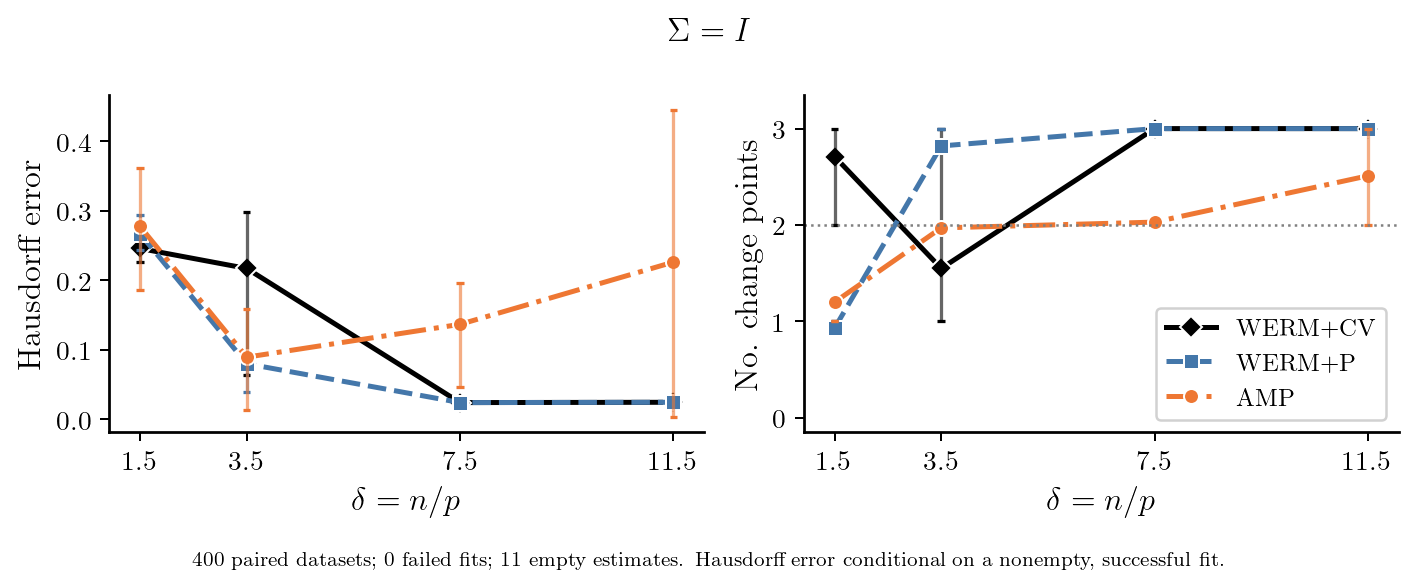

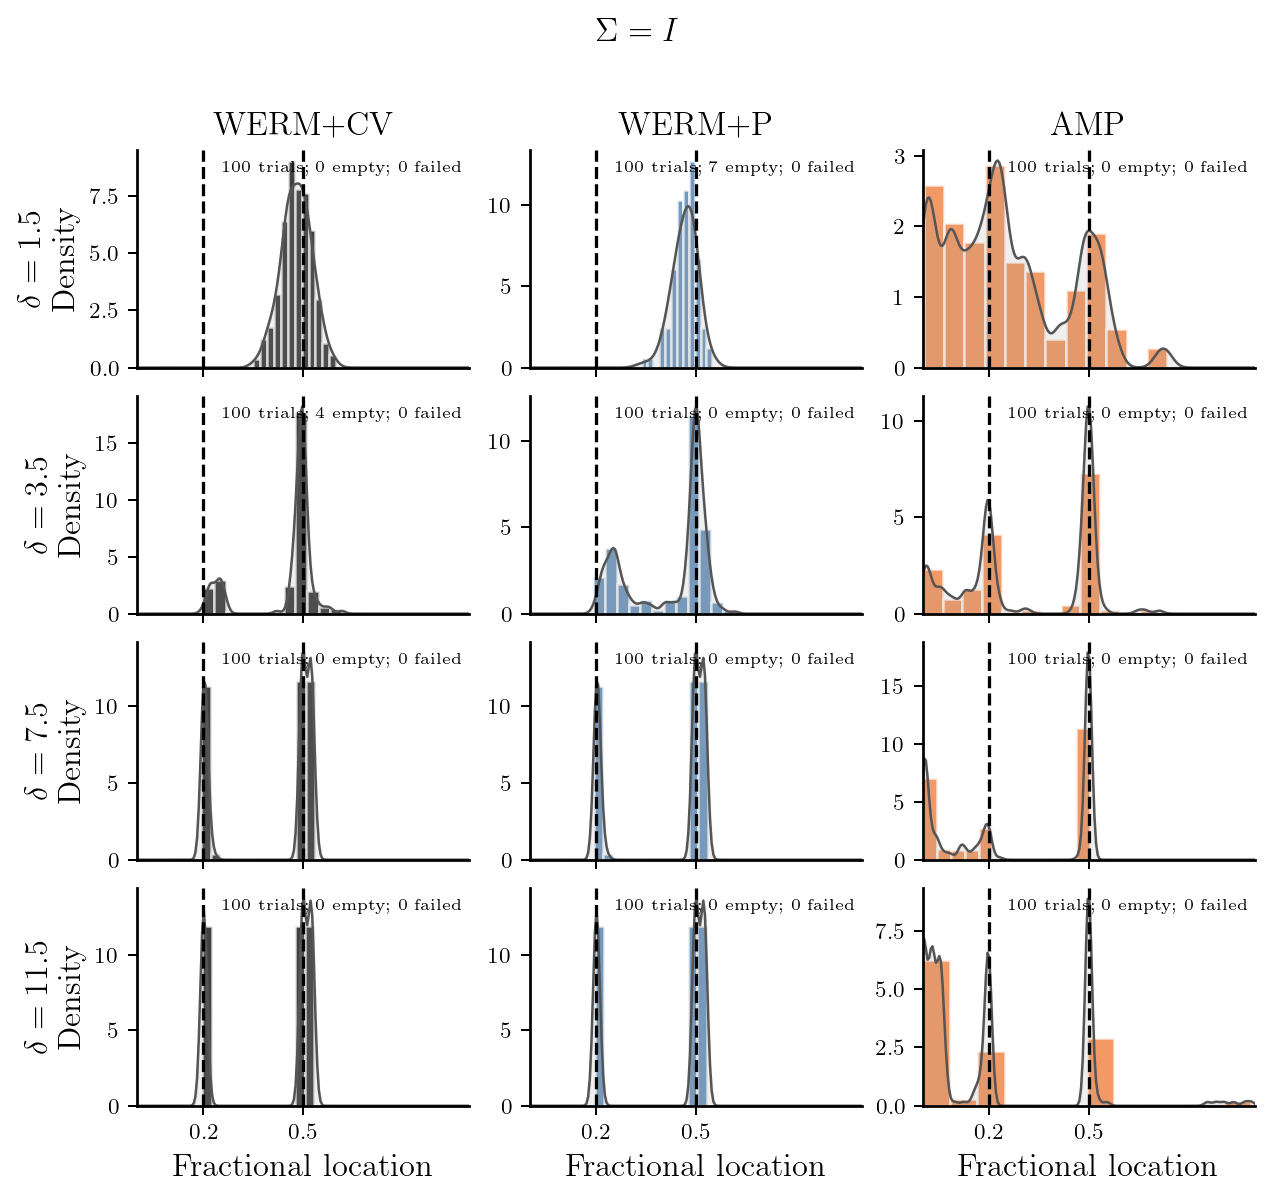

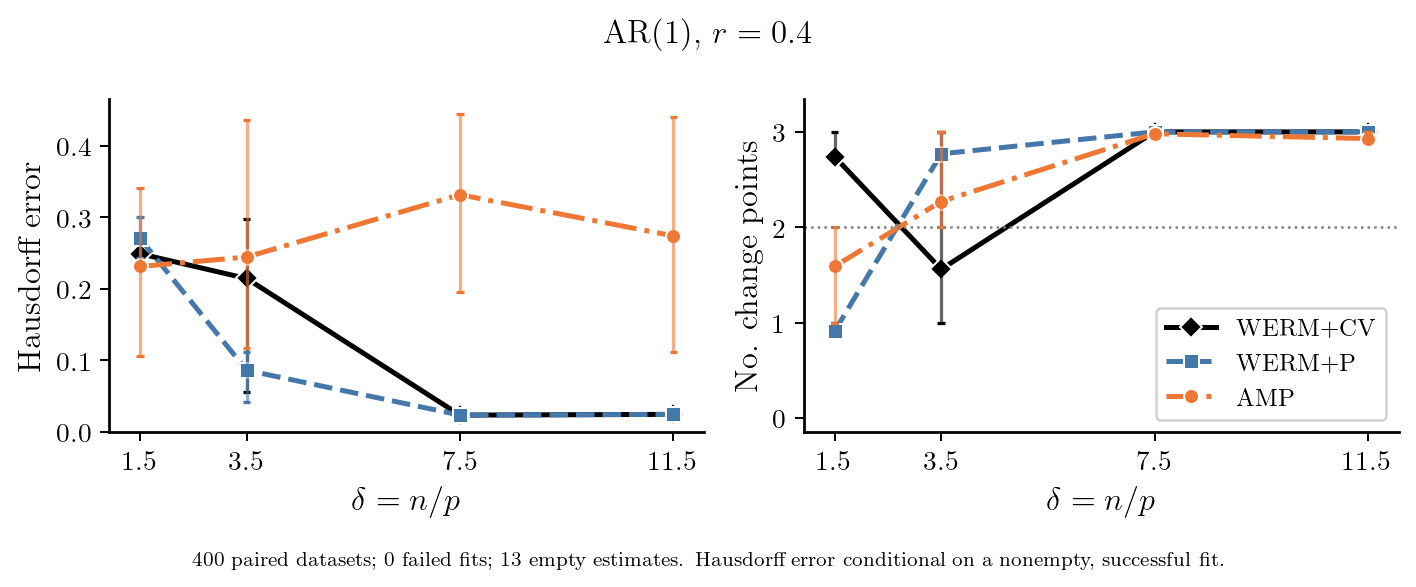

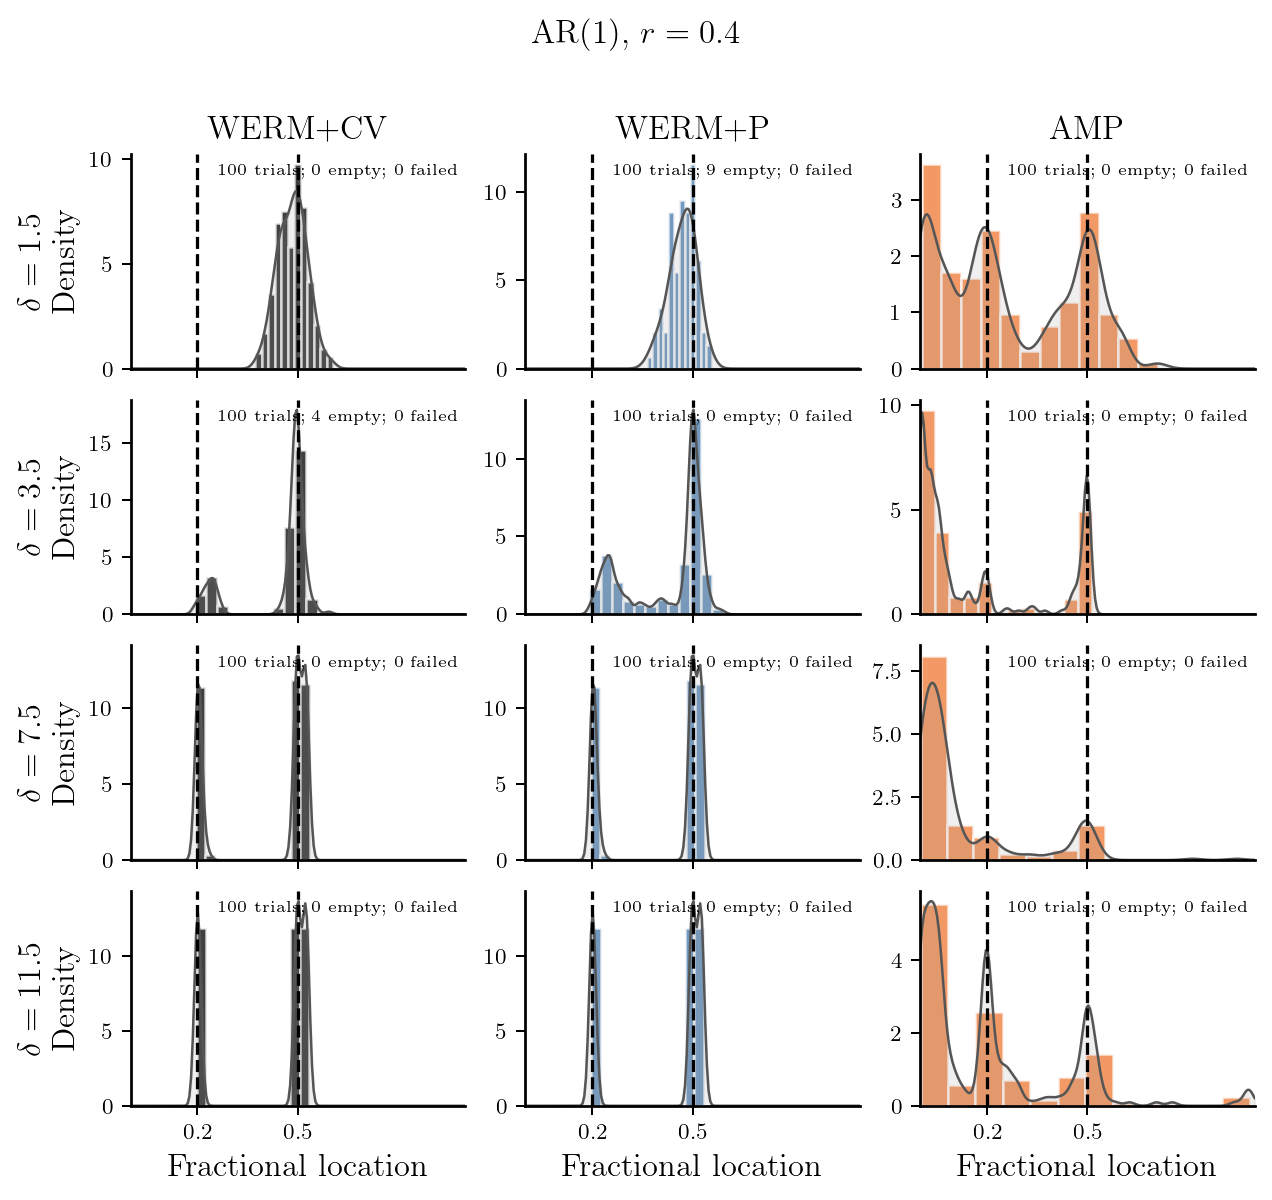

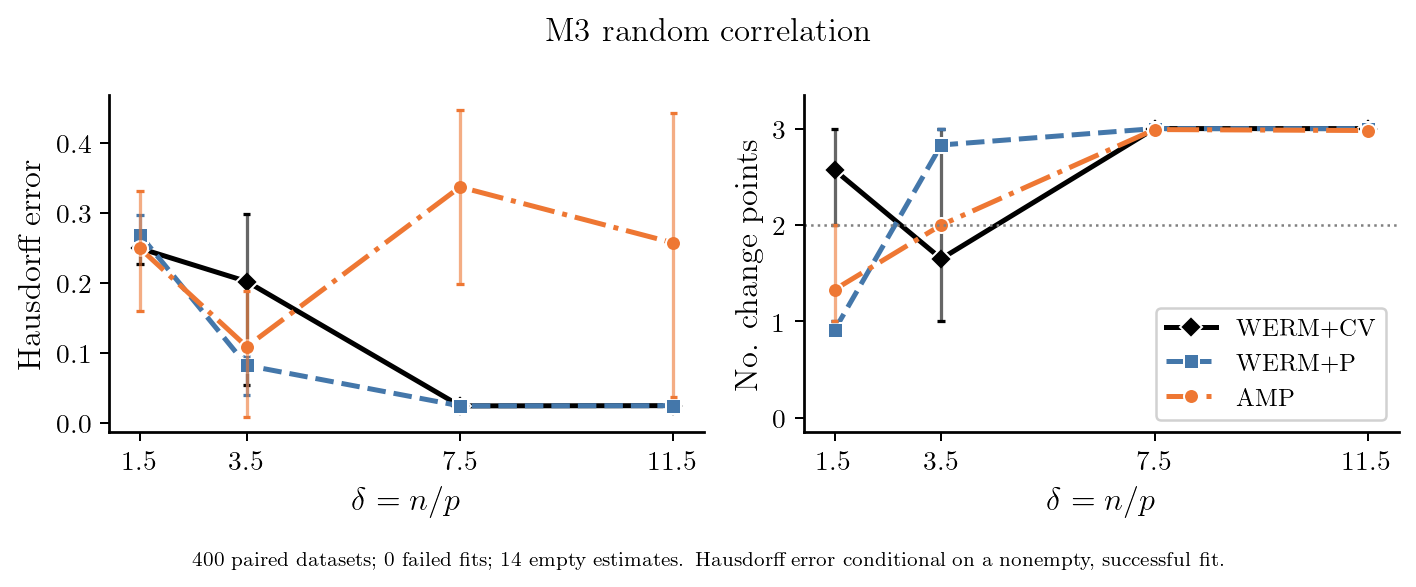

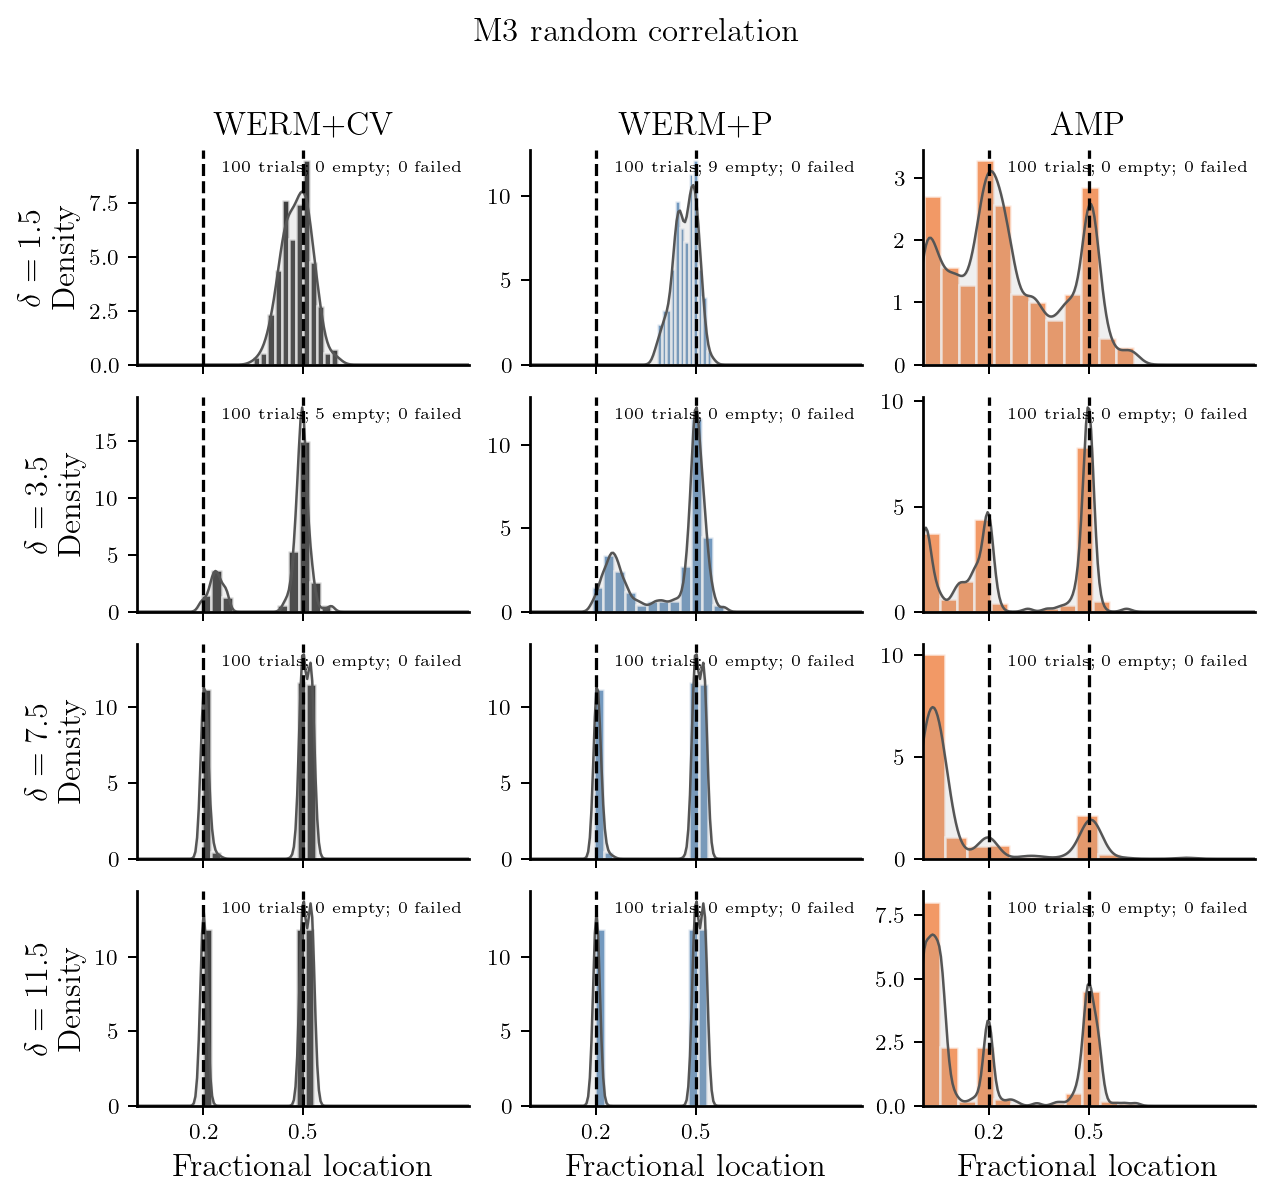

In [4]:
if PAYLOAD['records']:
    UNKNOWN_FIGURES = experiment.plot_study(
        PAYLOAD, study='unknown', output_dir=ROOT / 'figures' / 'unknown')
    for path in UNKNOWN_FIGURES:
        display(Image(filename=str(path)))
else:
    print('No completed trial snapshots yet. Refresh this cell after the run starts.')


## 2. Known number of change points

True changes are at $(0.25,0.45,0.70)n$, with exactly four working segments.
Compare fixed-count **WERM** and **AMP** to isolate their location estimates.
The count panel checks that successful fits return exactly three boundaries;
it is not a count-selection result. The Hausdorff curves and histograms use
the same conventions as above.

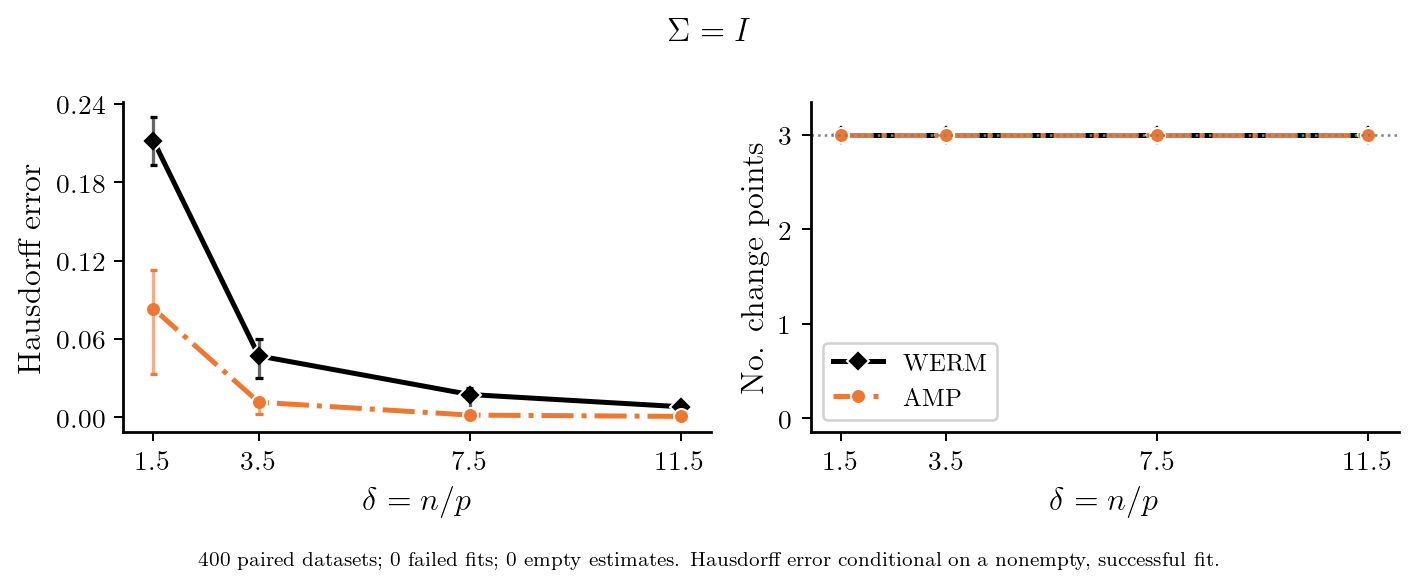

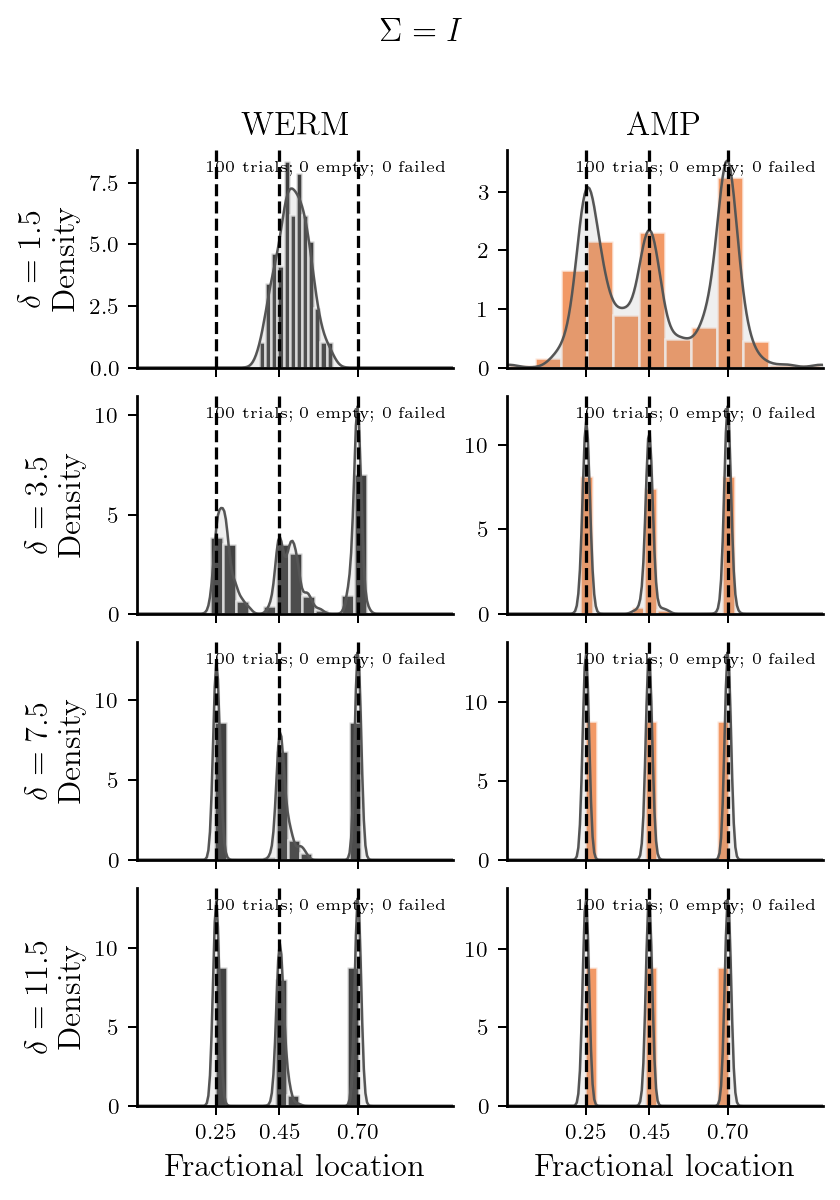

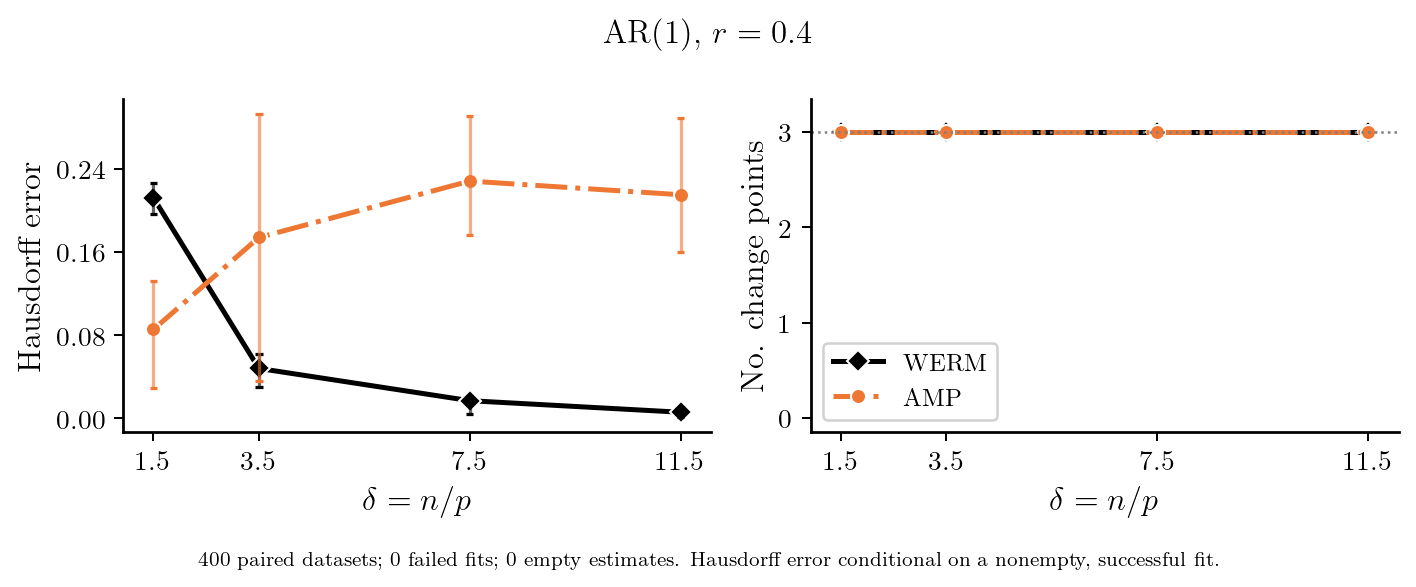

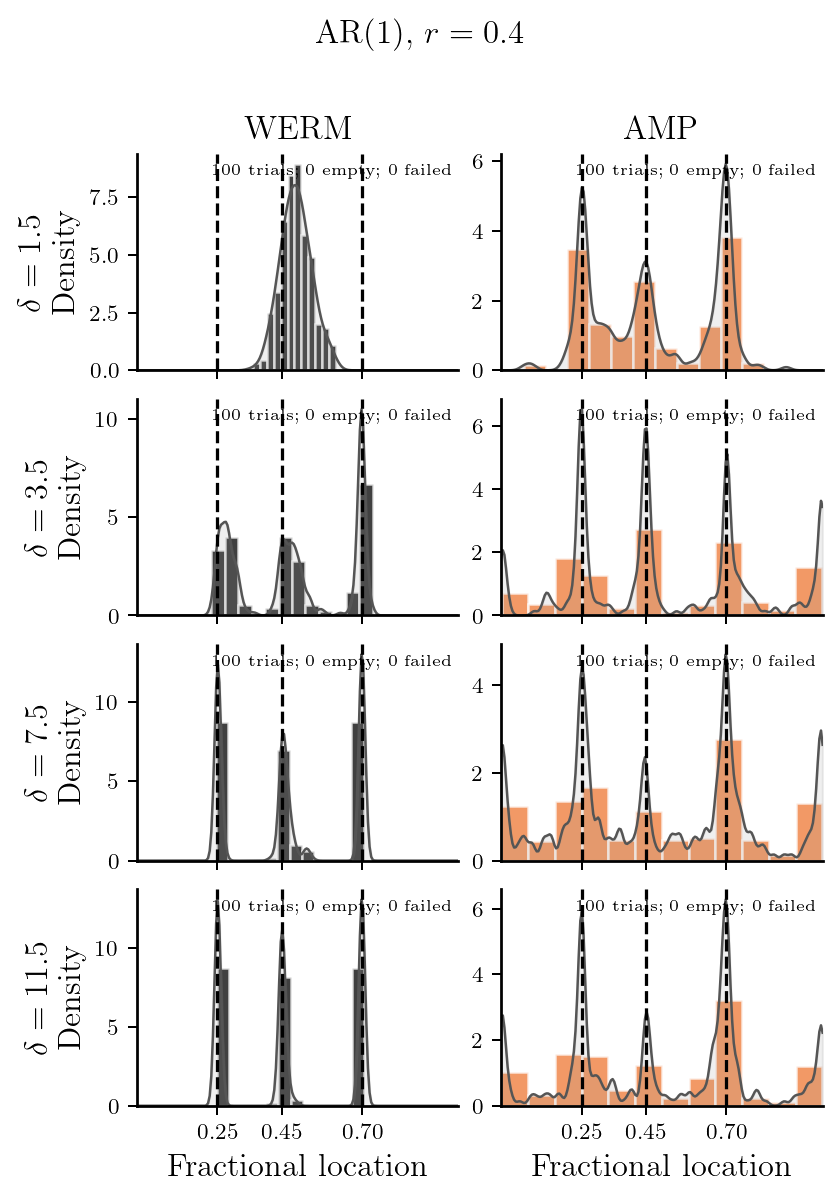

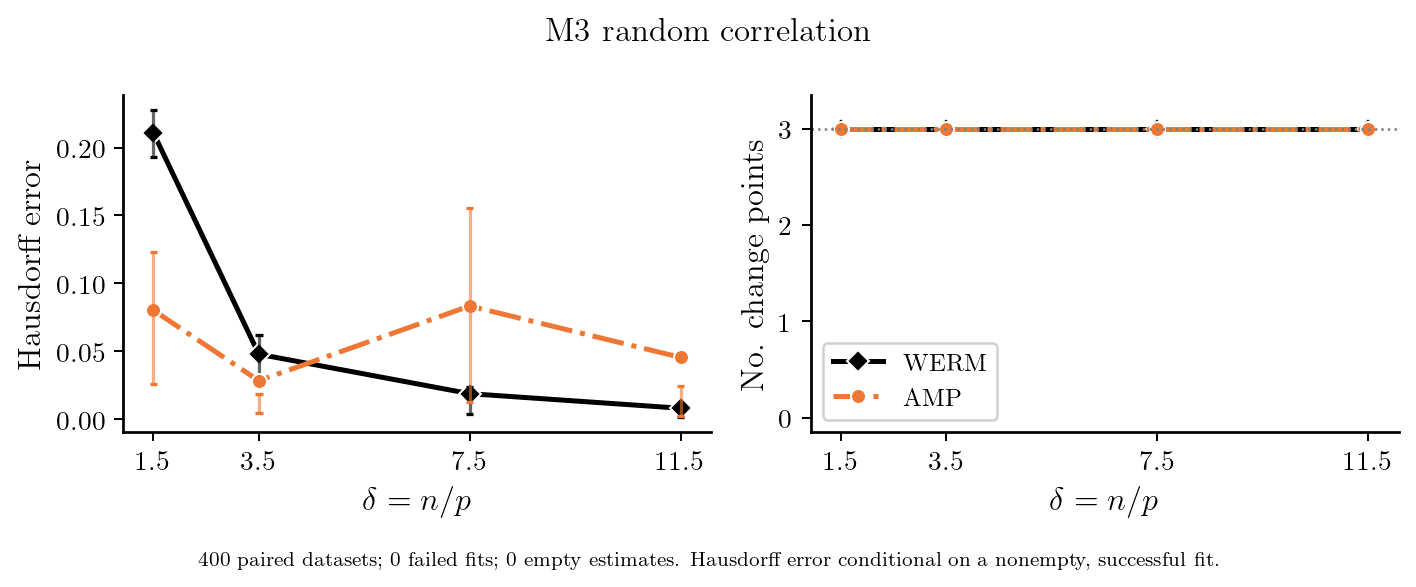

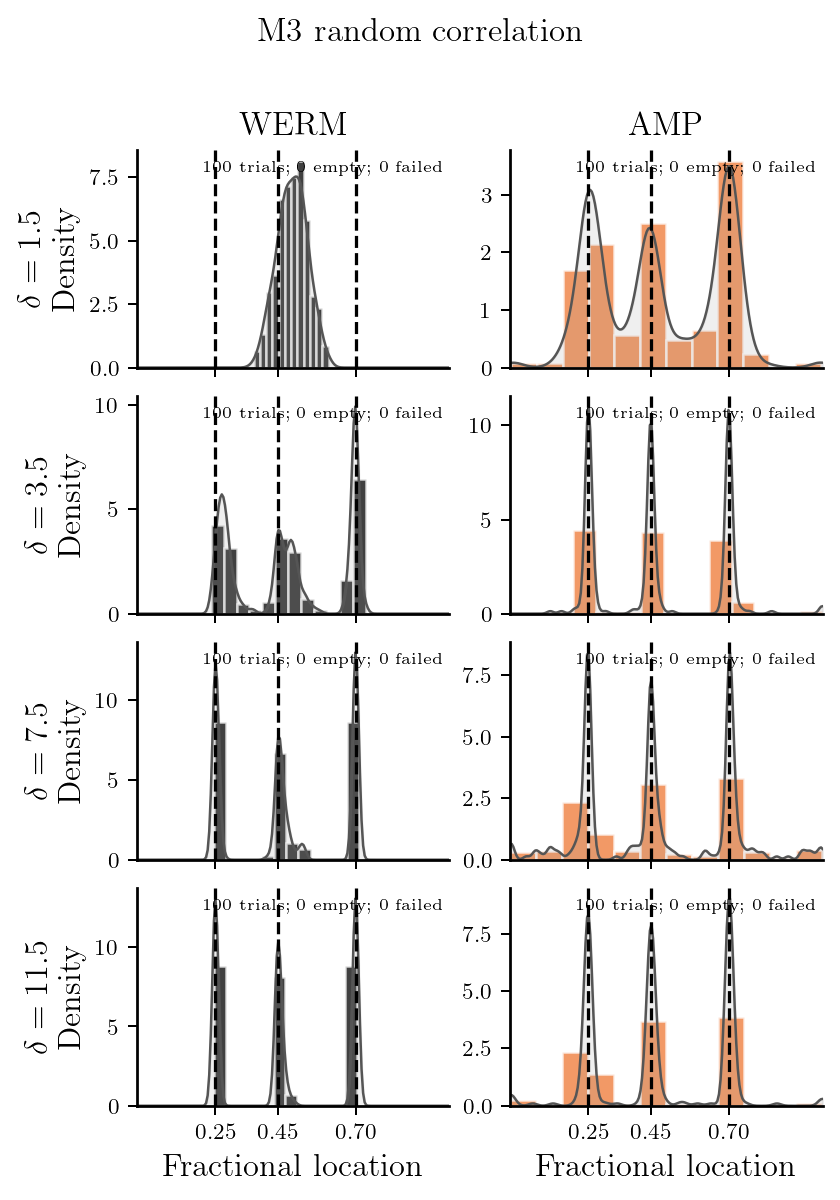

In [5]:
if PAYLOAD['records']:
    KNOWN_FIGURES = experiment.plot_study(
        PAYLOAD, study='known', output_dir=ROOT / 'figures' / 'known')
    for path in KNOWN_FIGURES:
        display(Image(filename=str(path)))
else:
    print('No completed trial snapshots yet.')


## AMP Monte Carlo resolution check

A separate numerical check uses **12 prechosen trial-0 datasets**: both
comparisons, all three covariances, and $\delta\in\{3.5,11.5\}$. It compares
the main run's 16,384 Monte Carlo draws per iteration with 65,536 draws, keeping
the data, initialization seed, Gaussian denoiser, iteration count and partition
prior fixed. The main experiment remains the 16,384-draw run; higher-resolution
outputs are not substituted into its curves.

In this check, all selected counts agree and nine of the twelve estimated
boundary sets agree exactly. Two unknown-count datasets show substantial
location changes, and one known-count dataset changes more modestly. This
small check therefore does **not** establish numerical stability of the AMP
location estimates. The table below retains both resolutions, including their
statuses and normalized Hausdorff errors. This cell only reads the saved
diagnostic; it does not rerun AMP.

In [6]:
RESOLUTION_FILE = ROOT / 'diagnostics' / 'amp_mc_resolution.csv'
if RESOLUTION_FILE.exists():
    import pandas as pd
    RESOLUTION = pd.read_csv(RESOLUTION_FILE)
    indexed = RESOLUTION.set_index(['study', 'covariance', 'delta', 'trial'])
    resolution_tables = {}
    for draws in (16384, 65536):
        names = [f'cp_{draws}', f'haus_{draws}',
                 f'count_{draws}', f'status_{draws}']
        resolution_tables[f'{draws:,} draws'] = indexed[names].rename(columns={
            f'cp_{draws}': 'boundaries', f'haus_{draws}': 'Hausdorff / n',
            f'count_{draws}': 'count', f'status_{draws}': 'status'})
    display(pd.concat(resolution_tables, axis=1).round(5))
    same_counts = RESOLUTION['count_16384'].eq(RESOLUTION['count_65536'])
    same_locations = RESOLUTION['cp_16384'].eq(RESOLUTION['cp_65536'])
    print(f'Identical counts: {same_counts.sum()}/{len(RESOLUTION)}; '
          f'identical boundary sets: {same_locations.sum()}/{len(RESOLUTION)}.')
    print('Largest absolute Hausdorff changes:',
          RESOLUTION['haus_difference'].abs().nlargest(3).round(5).tolist())
else:
    print('No saved resolution check for this run; no additional fits launched.')


16,384 draws                             \
                                       boundaries Hausdorff / n count status   
study   covariance delta trial                                                 
unknown identity   3.5   0             [136, 375]       0.03571     2     ok   
                   11.5  0            [450, 1152]       0.00435     2     ok   
        ar1        3.5   0            [1, 18, 35]       0.45000     3     ok   
                   11.5  0        [58, 115, 1145]       0.17478     3     ok   
        m3         3.5   0             [141, 347]       0.00429     2     ok   
                   11.5  0          [24, 81, 144]       0.43739     3     ok   
known   identity   3.5   0        [174, 342, 490]       0.03857     3     ok   
                   11.5  0      [575, 1035, 1610]       0.00000     3     ok   
        ar1        3.5   0          [5, 232, 595]       0.24286     3     ok   
                   11.5  0        [7, 1838, 1895]       0.34913     3     ok   
        m3         3.5   0        [177, 313, 490]       0.00286     3     ok   
                   11.5  0      [574, 1031, 1611]       0.00174     3     ok   

                                     65,536 draws                             
                                       boundaries Hausdorff / n count status  
study   covariance delta trial                                                
unknown identity   3.5   0             [136, 285]       0.09286     2     ok  
                   11.5  0            [450, 1152]       0.00435     2     ok  
        ar1        3.5   0            [1, 18, 35]       0.45000     3     ok  
                   11.5  0          [30, 89, 146]       0.43652     3     ok  
        m3         3.5   0             [141, 347]       0.00429     2     ok  
                   11.5  0          [24, 81, 144]       0.43739     3     ok  
known   identity   3.5   0        [174, 342, 490]       0.03857     3     ok  
                   11.5  0      [575, 1035, 1610]       0.00000     3     ok  
        ar1        3.5   0          [5, 232, 595]       0.24286     3     ok  
                   11.5  0       [28, 1814, 1872]       0.33870     3     ok  
        m3         3.5   0        [177, 313, 490]       0.00286     3     ok  
                   11.5  0      [574, 1031, 1611]       0.00174     3     ok

Identical counts: 12/12; identical boundary sets: 9/12.
Largest absolute Hausdorff changes: [0.26174, 0.05714, 0.01043]


## Reading the completed comparison

The known-count experiment shows a clear covariance contrast at the larger
sampling ratios: AMP localizes more accurately under the identity covariance,
whereas WERM localizes more accurately under the AR(1) and M3 covariances.
The unknown-count comparison is mixed. AMP is not uniformly better in the
isotropic case, and both WERM procedures overestimate the true two changes
by selecting three at the larger ratios. Their small Hausdorff errors should
therefore be read together with the count results. The Monte Carlo resolution
check also shows that individual AMP locations can depend on numerical
resolution; it does not justify a general stability claim.

The table below is computed from the loaded results at the largest sampling
ratio. `mean_haus` conditions on a successful, nonempty estimate. `mean_count`
includes valid empty estimates as zero and excludes failed fits.
`correct_count_rate` and `empty_rate` use all completed trials as their
denominator; failed fits are not correct-count estimates or valid empty
estimates. The success and failure columns make these denominators explicit.
The known-count correct-count rate checks the required output size, rather
than evaluating count selection.

In [7]:
if not SUMMARY.empty:
    largest_delta = max(PAYLOAD['specification']['deltas'])
    endpoint_columns = ['study', 'covariance', 'method', 'trials', 'successes',
        'failure_rate', 'mean_haus', 'mean_count', 'correct_count_rate', 'empty_rate']
    ENDPOINT_SUMMARY = SUMMARY.loc[
        SUMMARY['delta'].eq(largest_delta), endpoint_columns].copy()
    print(f'Summary at delta={largest_delta:g}.')
    if not CURRENT_STATUS['complete']:
        print('PARTIAL SNAPSHOT: the interpretation above concerns the full design; '
              'inspect the completed-trial counts shown here.')
    display(ENDPOINT_SUMMARY.round(5))
else:
    print('No completed trials to summarize.')


Summary at delta=11.5.


,study,covariance,method,trials,successes,failure_rate,mean_haus,mean_count,correct_count_rate,empty_rate
2,known,ar1,WERM,100,100,0.0,0.00599,3.00,1.00,0.0
3,known,ar1,AMP,100,100,0.0,0.21497,3.00,1.00,0.0
10,known,identity,WERM,100,100,0.0,0.00807,3.00,1.00,0.0
11,known,identity,AMP,100,100,0.0,0.00068,3.00,1.00,0.0
18,known,m3,WERM,100,100,0.0,0.00814,3.00,1.00,0.0
19,known,m3,AMP,100,100,0.0,0.04557,3.00,1.00,0.0
27,unknown,ar1,WERM+CV,100,100,0.0,0.02451,3.00,0.00,0.0
28,unknown,ar1,WERM+P,100,100,0.0,0.02451,3.00,0.00,0.0
29,unknown,ar1,AMP,100,100,0.0,0.27390,2.93,0.07,0.0
39,unknown,identity,WERM+CV,100,100,0.0,0.02457,3.00,0.00,0.0


## Reproducibility and interpretation

`tools/werm_amp_experiment.py` defines the data generator, covariance matrices,
shared exact prior, estimators, resumable execution and plotting. Its saved
specification records the settings used for this run. The local AMP adapter
imports the implementation from `../AMP_chgpt_reg`; that repository must be
available beside `WeightedERM-reference`.

Compare all three covariance settings, together with empty/failure frequencies
and available trial counts. Finite-sample changes in AMP performance under
correlation are observations from this experiment, not a predetermined outcome
or a theorem. The mild AR(1) and M3 covariance choices are matched to existing
paper experiments and are not selected after observing the methods' ranking.